# ML-012: Crop Type Classification from Basic Soil Data

## Project Overview
This project uses Machine Learning to classify crop types
based on soil nutrients and environmental conditions.

## Objective
To develop a supervised machine learning classification
model using soil and weather parameters.

## Input Features
- Nitrogen (N)
- Phosphorus (P)
- Potassium (K)
- Temperature
- Humidity
- Soil pH
- Rainfall

## Target
Crop Label

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
df = pd.read_csv('dataset/Crop_recommendation.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [9]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 2200
Total Columns: 8


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


In [11]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [12]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [13]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [14]:
print("Total Crop Categories:", df['label'].nunique())
print("\nCrop Names:")
print(df['label'].unique())

Total Crop Categories: 22

Crop Names:
<ArrowStringArray>
[       'rice',       'maize',    'chickpea', 'kidneybeans',  'pigeonpeas',
   'mothbeans',    'mungbean',   'blackgram',      'lentil', 'pomegranate',
      'banana',       'mango',      'grapes',  'watermelon',   'muskmelon',
       'apple',      'orange',      'papaya',     'coconut',      'cotton',
        'jute',      'coffee']
Length: 22, dtype: str


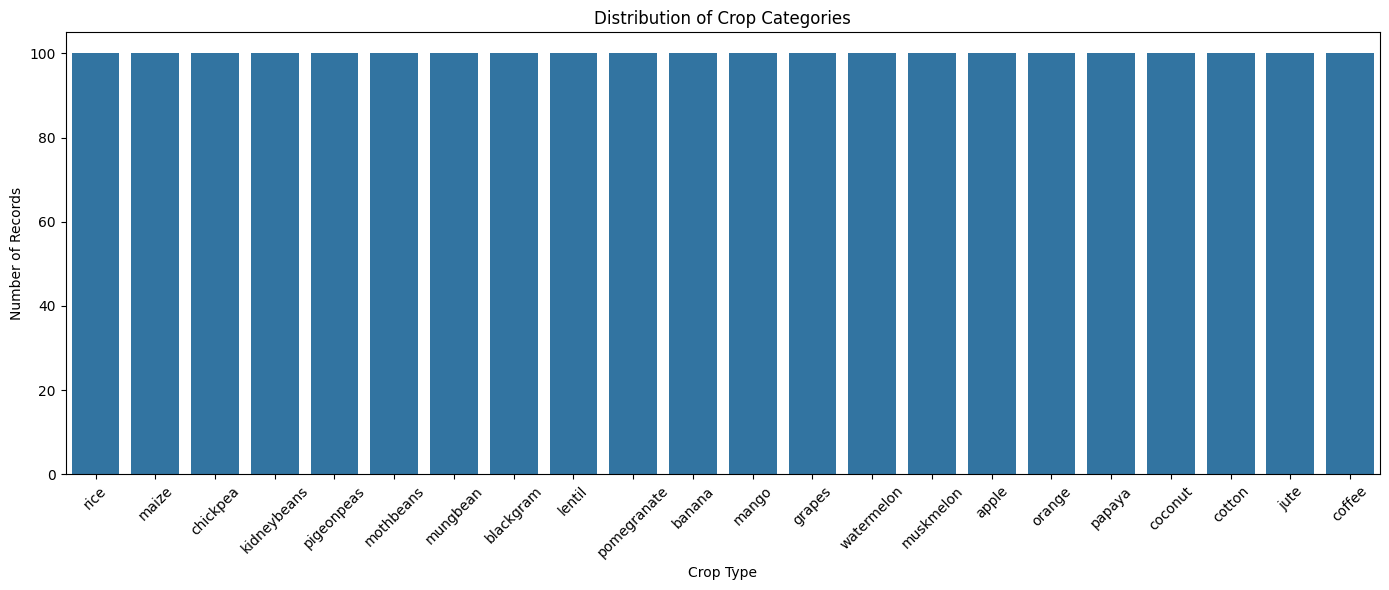

In [15]:
plt.figure(figsize=(14, 6))

sns.countplot(data=df, x='label', order=df['label'].value_counts().index)

plt.title("Distribution of Crop Categories")
plt.xlabel("Crop Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

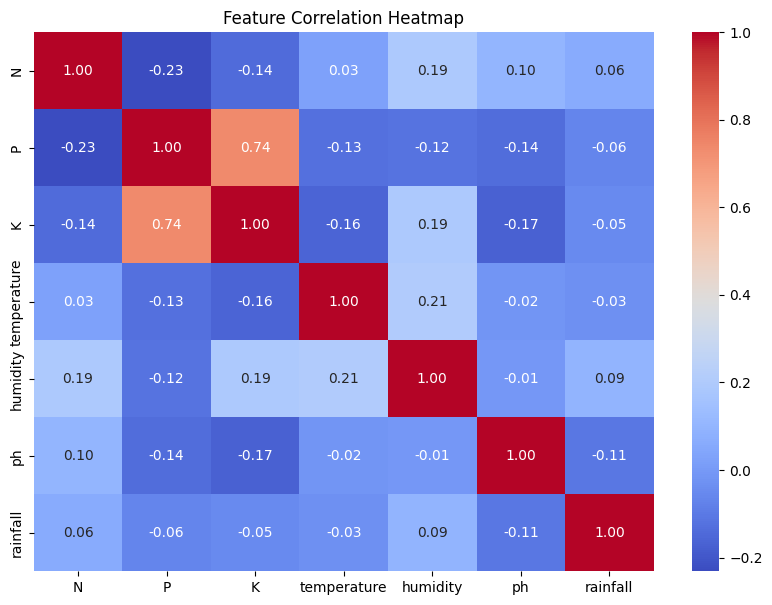

In [16]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

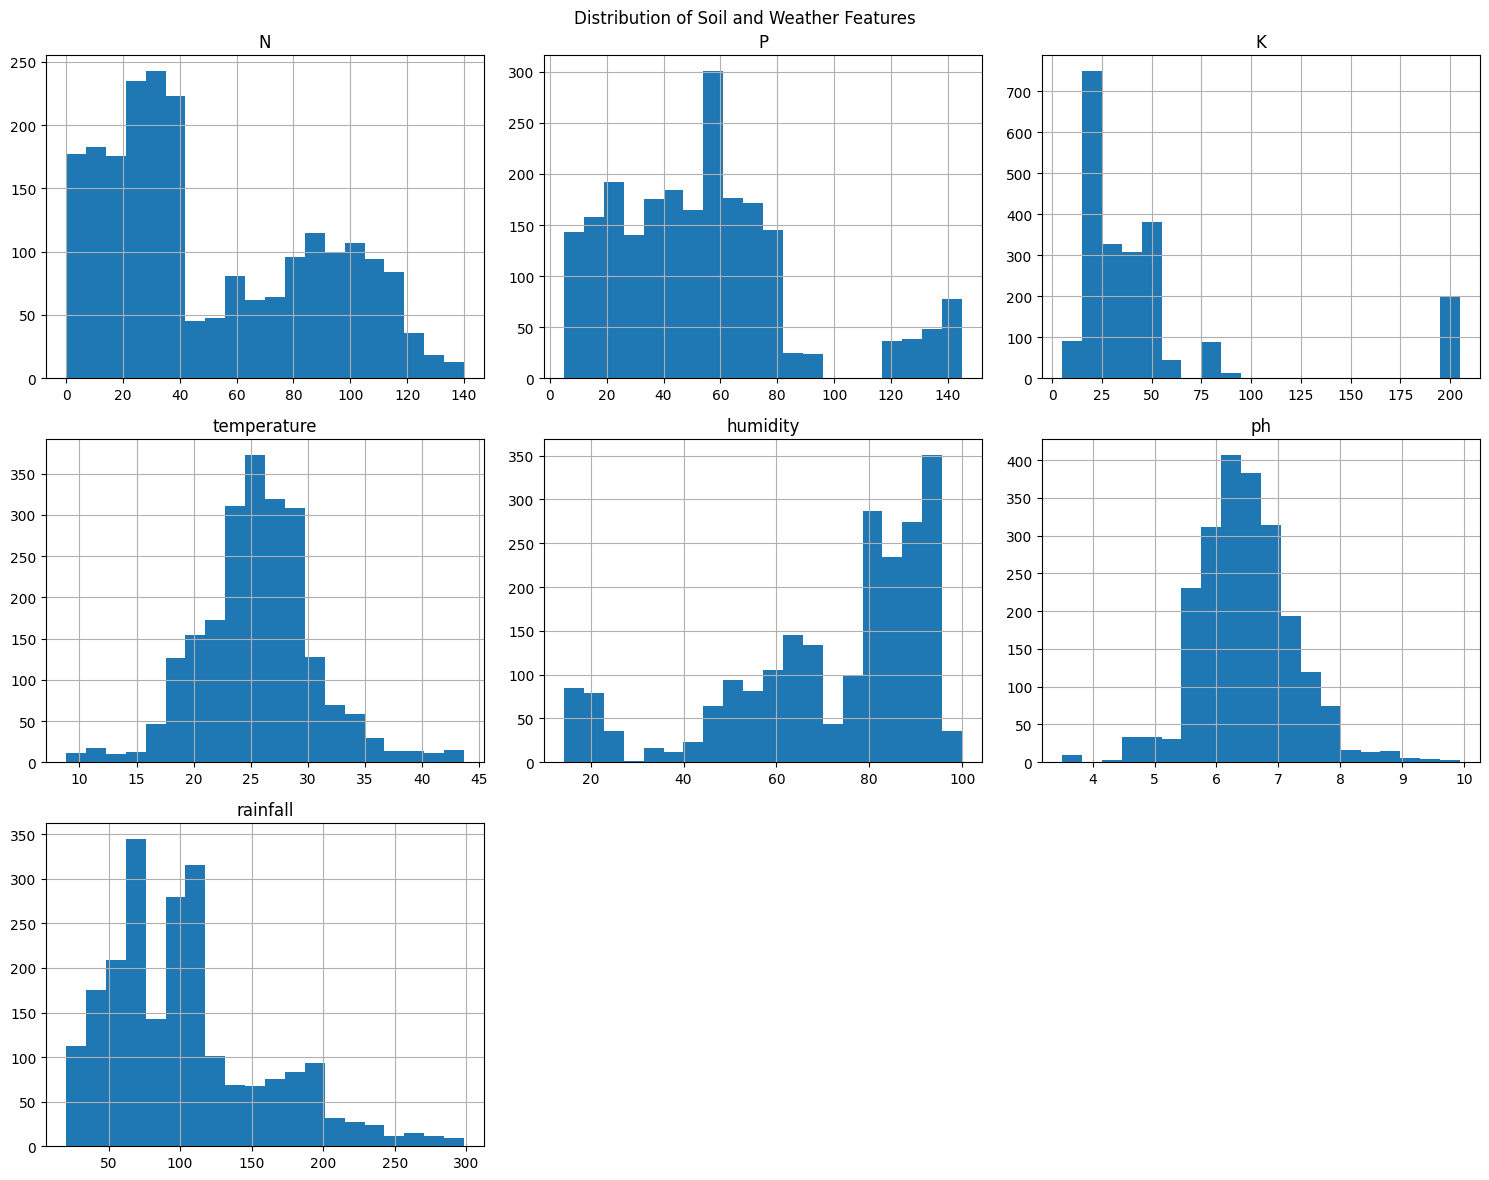

In [17]:
df.hist(figsize=(15, 12), bins=20)

plt.suptitle("Distribution of Soil and Weather Features")
plt.tight_layout()
plt.show()

In [18]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Total Missing Values: 0


In [19]:
print("Before:", df.shape)

df = df.drop_duplicates()

print("After:", df.shape)

Before: (2200, 8)
After: (2200, 8)


In [20]:
X = df.drop('label', axis=1)
y = df['label']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (2200, 7)
Target Shape: (2200,)


In [21]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Crop Categories:", label_encoder.classes_)

Crop Categories: ['apple' 'banana' 'blackgram' 'chickpea' 'coconut' 'coffee' 'cotton'
 'grapes' 'jute' 'kidneybeans' 'lentil' 'maize' 'mango' 'mothbeans'
 'mungbean' 'muskmelon' 'orange' 'papaya' 'pigeonpeas' 'pomegranate'
 'rice' 'watermelon']


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1760, 7)
Testing Data: (440, 7)


In [23]:
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Total Samples:", len(X_train) + len(X_test))

Training Samples: 1760
Testing Samples: 440
Total Samples: 2200


In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, classification_report

In [26]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    
    "KNN": KNeighborsClassifier(n_neighbors=5),
    
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

print("Models initialized successfully!")

Models initialized successfully!


In [27]:
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    print(f"{name} trained successfully!")

Decision Tree trained successfully!
Random Forest trained successfully!
KNN trained successfully!
Logistic Regression trained successfully!


In [29]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "Accuracy": round(accuracy * 100, 2)
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy
1,Random Forest,99.55
0,Decision Tree,97.95
2,KNN,97.73
3,Logistic Regression,95.00


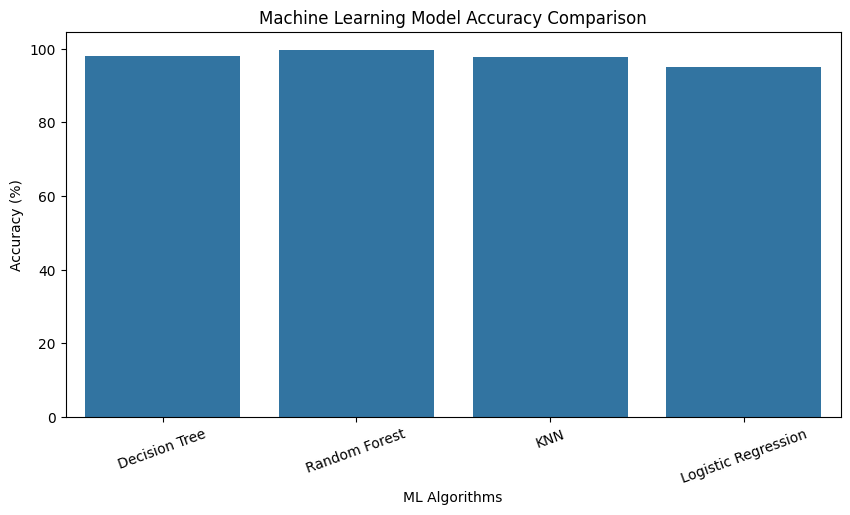

In [30]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("ML Algorithms")
plt.xticks(rotation=20)

plt.show()

In [31]:
best_model_name = results_df.sort_values(
    by="Accuracy",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [32]:
best_model_name = results_df.sort_values(
    by="Accuracy",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


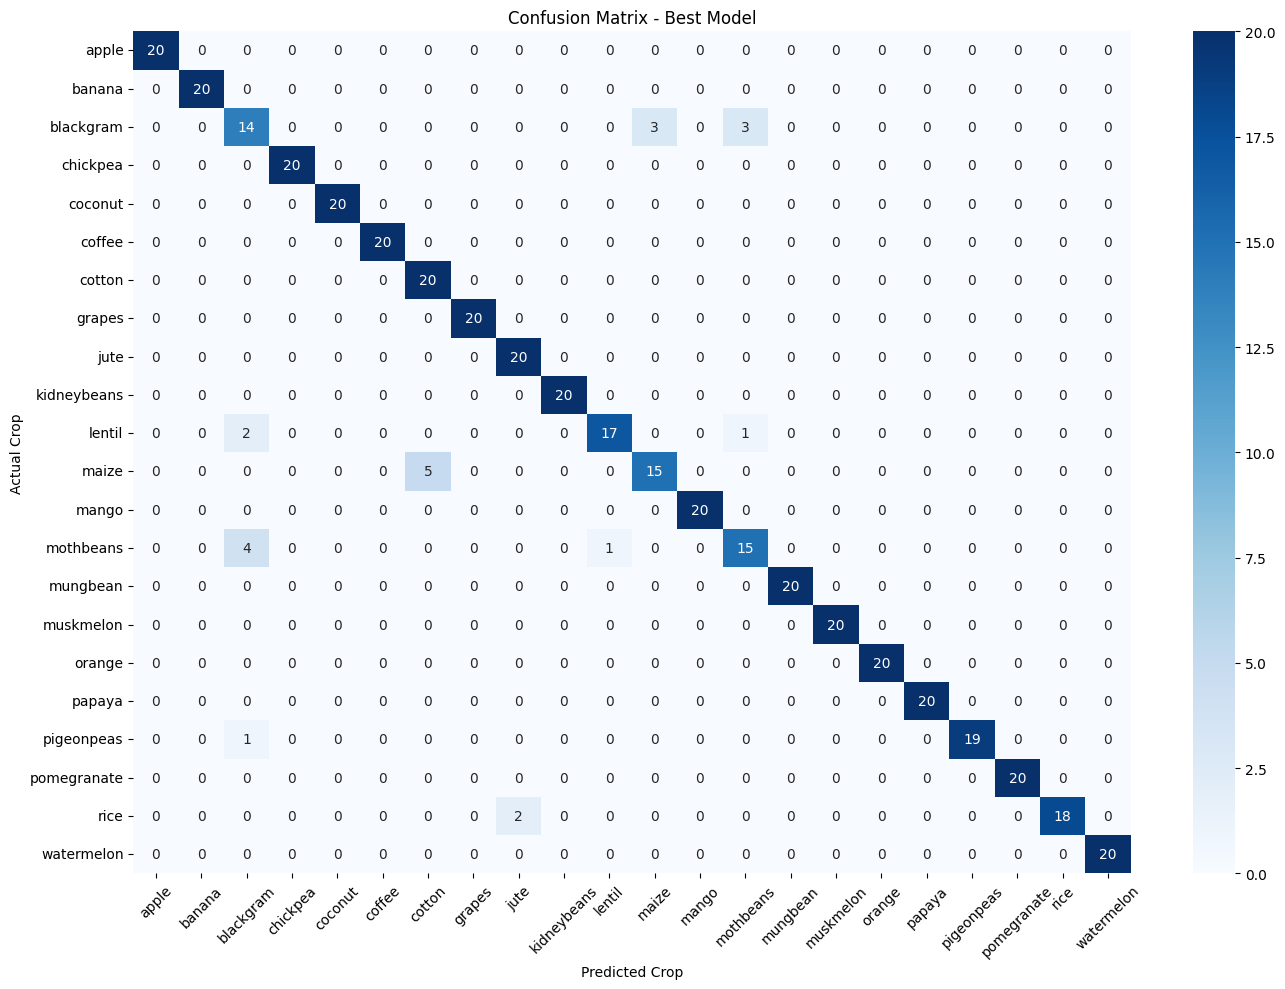

In [33]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Best Model")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Model:", best_model_name)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, average='weighted'
))

print("Recall:", recall_score(
    y_test, y_pred, average='weighted'
))

print("F1 Score:", f1_score(
    y_test, y_pred, average='weighted'
))

Model: Random Forest
Accuracy: 0.95
Precision: 0.9519549562611763
Recall: 0.95
F1 Score: 0.9499711527952864


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Model:", best_model_name)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, average='weighted'
))

print("Recall:", recall_score(
    y_test, y_pred, average='weighted'
))

print("F1 Score:", f1_score(
    y_test, y_pred, average='weighted'
))

Model: Random Forest
Accuracy: 0.95
Precision: 0.9519549562611763
Recall: 0.95
F1 Score: 0.9499711527952864


,Feature,Importance
6,rainfall,0.230184
4,humidity,0.224227
2,K,0.175393
1,P,0.150850
0,N,0.096363
3,temperature,0.072375
5,ph,0.050608


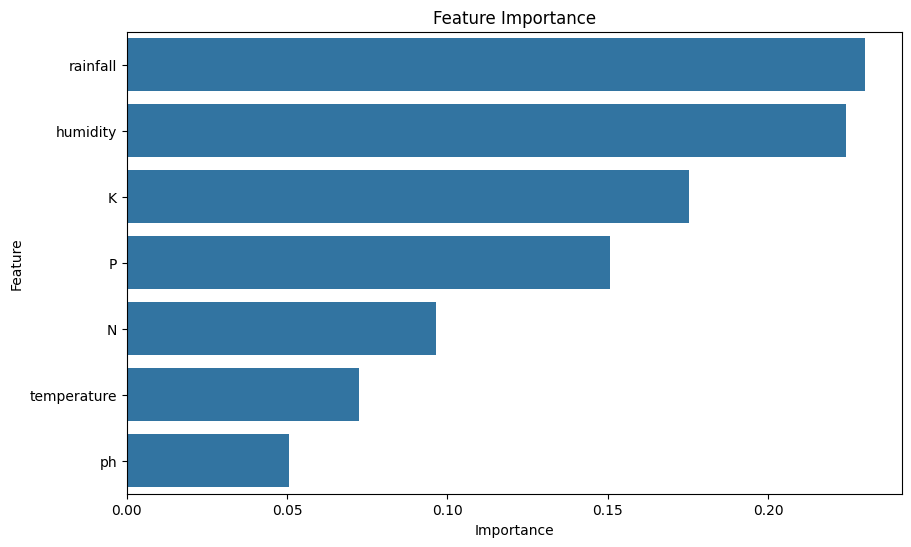

In [36]:
if hasattr(best_model, 'feature_importances_'):

    importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': best_model.feature_importances_
    })

    importance = importance.sort_values(
        by='Importance',
        ascending=False
    )

    display(importance)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=importance,
        x='Importance',
        y='Feature'
    )

    plt.title("Feature Importance")
    plt.show()

else:
    print("Feature importance is not directly available for this model.")

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred = best_model.predict(X_test)

print("MODEL:", best_model_name)
print("-" * 50)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

MODEL: Random Forest
--------------------------------------------------
Accuracy: 0.9954545454545455
Precision: 0.9956709956709956
Recall: 0.9954545454545455
F1 Score: 0.9954517027687759

Classification Report:

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.

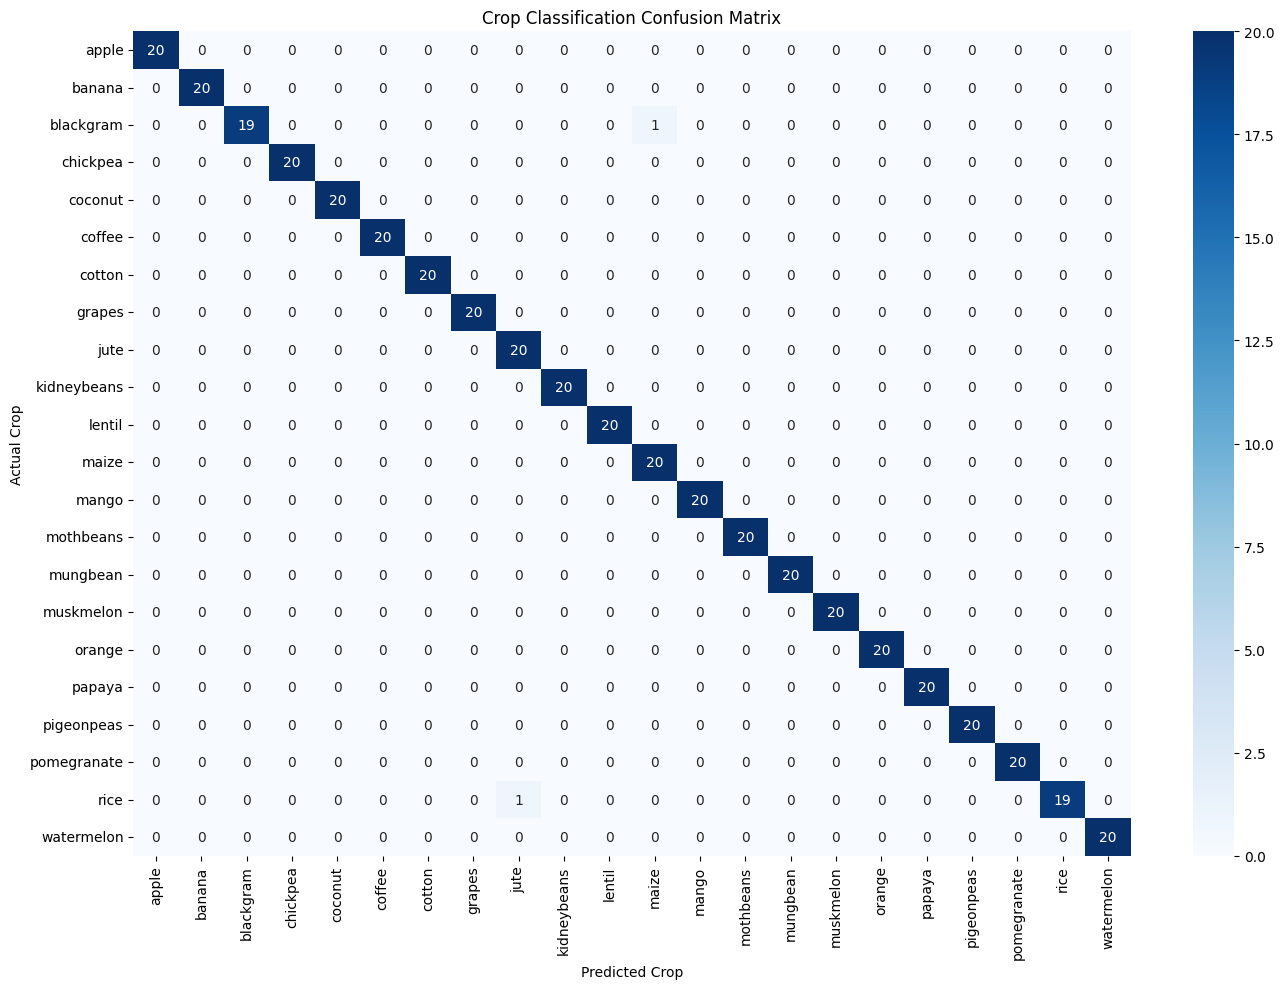

In [38]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Crop Classification Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")

plt.tight_layout()
plt.show()

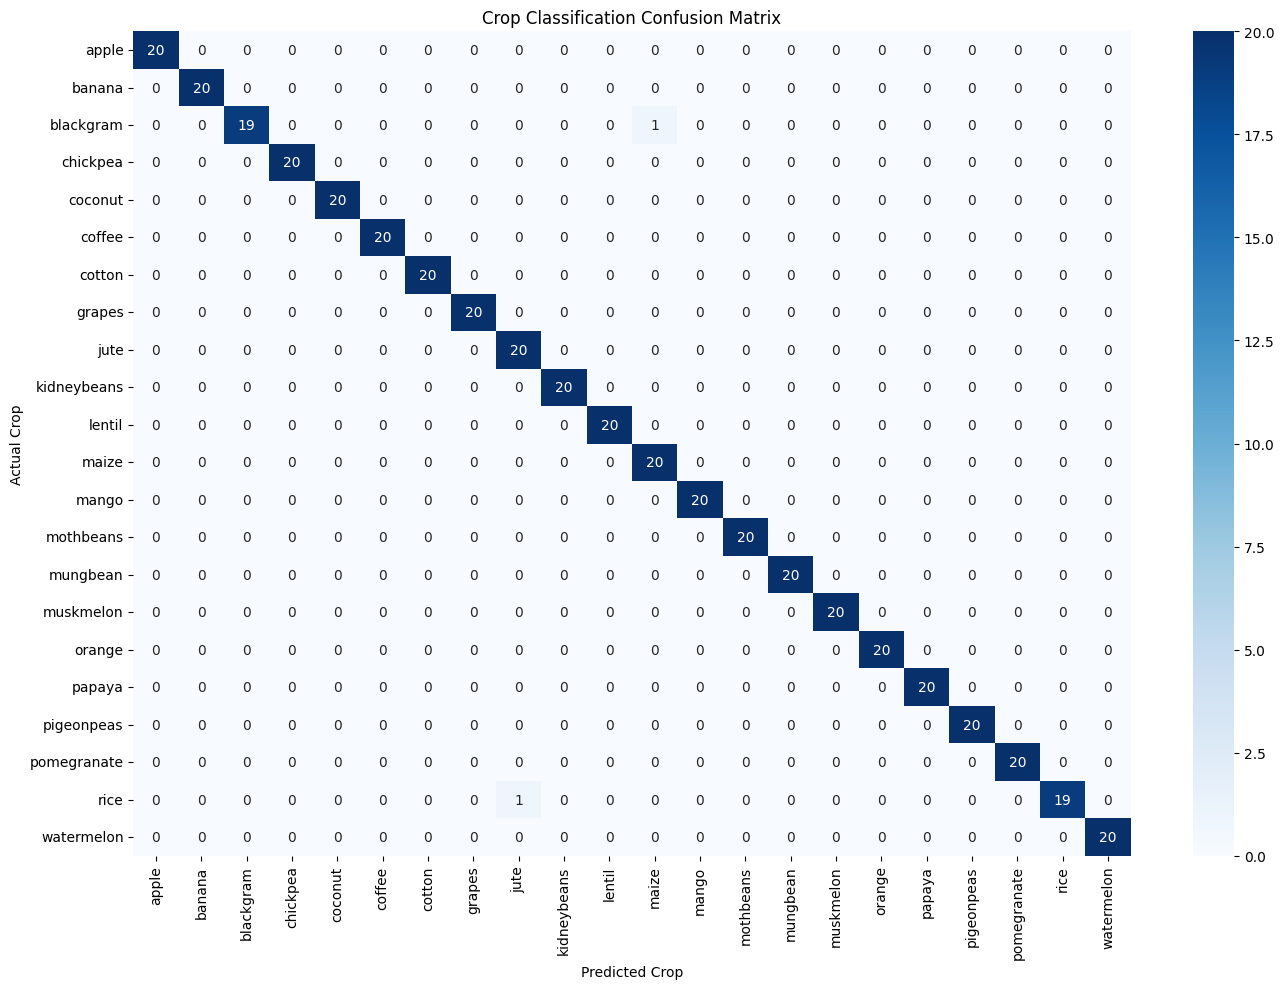

In [39]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Crop Classification Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")

plt.tight_layout()
plt.show()

In [40]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    best_model,
    X,
    y_encoded,
    cv=5,
    scoring='accuracy'
)

print("Cross Validation Scores:", cv_scores)

print("Mean Accuracy:", cv_scores.mean() * 100)

print("Standard Deviation:", cv_scores.std())

Cross Validation Scores: [0.99772727 0.99318182 0.99772727 0.99545455 0.98863636]
Mean Accuracy: 99.45454545454545
Standard Deviation: 0.003401506715249021


In [41]:
def predict_crop(N, P, K, temperature, humidity, ph, rainfall):

    input_data = pd.DataFrame([{
        'N': N,
        'P': P,
        'K': K,
        'temperature': temperature,
        'humidity': humidity,
        'ph': ph,
        'rainfall': rainfall
    }])

    prediction = best_model.predict(input_data)

    predicted_crop = label_encoder.inverse_transform(prediction)

    return predicted_crop[0]

In [42]:
result = predict_crop(
    N=90,
    P=42,
    K=43,
    temperature=25.5,
    humidity=80,
    ph=6.5,
    rainfall=200
)

print("Predicted Crop:", result)

Predicted Crop: rice


In [46]:
print("CROP TYPE CLASSIFICATION SYSTEM")
print("=" * 40)

N = float(input("Enter Nitrogen (N): "))
P = float(input("Enter Phosphorus (P): "))
K = float(input("Enter Potassium (K): "))

temperature = float(input("Enter Temperature: "))
humidity = float(input("Enter Humidity: "))
ph = float(input("Enter Soil pH: "))
rainfall = float(input("Enter Rainfall: "))

result = predict_crop(
    N, P, K,
    temperature,
    humidity,
    ph,
    rainfall
)

print("\n" + "=" * 40)
print("PREDICTED CROP:", result.upper())
print("=" * 40)

CROP TYPE CLASSIFICATION SYSTEM


Enter Nitrogen (N):  15
Enter Phosphorus (P):  15
Enter Potassium (K):  15
Enter Temperature:  1
Enter Humidity:  1
Enter Soil pH:  2
Enter Rainfall:  2



PREDICTED CROP: KIDNEYBEANS


In [45]:
print("=" * 55)
print("ML-012 PROJECT SUMMARY")
print("=" * 55)

print("Project: Crop Type Classification")
print("Dataset Records:", len(df))
print("Input Features:", X.shape[1])
print("Crop Categories:", len(label_encoder.classes_))

print("Best Model:", best_model_name)

print(
    "Model Accuracy:",
    round(accuracy_score(y_test, y_pred) * 100, 2),
    "%"
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nPROJECT DEVELOPMENT COMPLETED!")

ML-012 PROJECT SUMMARY
Project: Crop Type Classification
Dataset Records: 2200
Input Features: 7
Crop Categories: 22
Best Model: Random Forest
Model Accuracy: 99.55 %
Training Samples: 1760
Testing Samples: 440

PROJECT DEVELOPMENT COMPLETED!


In [56]:
import os

os.makedirs('models', exist_ok=True)

print("Models folder created successfully!")
print("Folder location:", os.path.abspath('models'))

Models folder created successfully!
Folder location: C:\Users\rajan\ML-012-Crop-Classification\models


In [58]:
import joblib

joblib.dump(best_model, 'models/best_crop_model.pkl')

joblib.dump(label_encoder, 'models/label_encoder.pkl')

joblib.dump(list(X.columns), 'models/feature_columns.pkl')

print("Model saved successfully!")

Model saved successfully!


In [59]:
import joblib
import os

model_path = 'models/best_crop_model.pkl'

if os.path.exists(model_path):
    loaded_model = joblib.load(model_path)
    print("Model loaded successfully!")
else:
    print("Model file not found!")

Model loaded successfully!


In [60]:
import pandas as pd

test_data = pd.DataFrame([{
    'N': 90,
    'P': 42,
    'K': 43,
    'temperature': 25.5,
    'humidity': 80,
    'ph': 6.5,
    'rainfall': 200
}])

prediction = loaded_model.predict(test_data)

predicted_crop = label_encoder.inverse_transform(prediction)

print("Input Data:")
display(test_data)

print("Predicted Crop:", predicted_crop[0].upper())

Input Data:


,N,P,K,temperature,humidity,ph,rainfall
0,90,42,43,25.5,80,6.5,200


Predicted Crop: RICE


In [61]:
test_cases = pd.DataFrame([
    [90, 42, 43, 25.5, 80, 6.5, 200],
    [40, 60, 20, 22.0, 65, 6.0, 100],
    [100, 20, 40, 30.0, 70, 7.0, 150],
    [20, 30, 10, 18.0, 50, 5.5, 80],
    [80, 50, 30, 28.0, 75, 6.8, 180]
], columns=[
    'N', 'P', 'K', 'temperature',
    'humidity', 'ph', 'rainfall'
])

predictions = loaded_model.predict(test_cases)

test_cases['Predicted Crop'] = label_encoder.inverse_transform(
    predictions
)

display(test_cases)

,N,P,K,temperature,humidity,ph,rainfall,Predicted Crop
0,90,42,43,25.5,80,6.5,200,rice
1,40,60,20,22.0,65,6.0,100,pigeonpeas
2,100,20,40,30.0,70,7.0,150,coffee
3,20,30,10,18.0,50,5.5,80,orange
4,80,50,30,28.0,75,6.8,180,jute


In [62]:
from sklearn.metrics import accuracy_score

test_predictions = loaded_model.predict(X_test)

accuracy = accuracy_score(y_test, test_predictions)

print(f"Model Testing Accuracy: {accuracy * 100:.2f}%")

Model Testing Accuracy: 99.55%
